# SPHEREx / IRSA: processamento das três imagens e GIF

Cada frame é um dos **três mosaicos originais por visita**: maio/2025 (3 exposições), novembro/2025 (7) e abril/2026 (5). As três imagens passam pelo mesmo processamento: WCS celeste, reprojeção na grade comum, conversão MJy/sr para mJy/pixel, medição em abertura e subtração do fundo em anel. O contraste é igual nos três frames.

Estes são os mosaicos 2D da faixa D6 já selecionada (centro 4,885 ± 0,120 µm), não cubos espectrais completos por época. Os planos de 3,3 µm e contínuo do exemplo M101 não estão nesses três FITS, portanto não há mapa PAH aqui.

[Tutorial IRSA](https://caltech-ipac.github.io/irsa-tutorials/spherex-mosaic/). Para refazer: `uv run --extra viz spherex-tracking three-visits`.

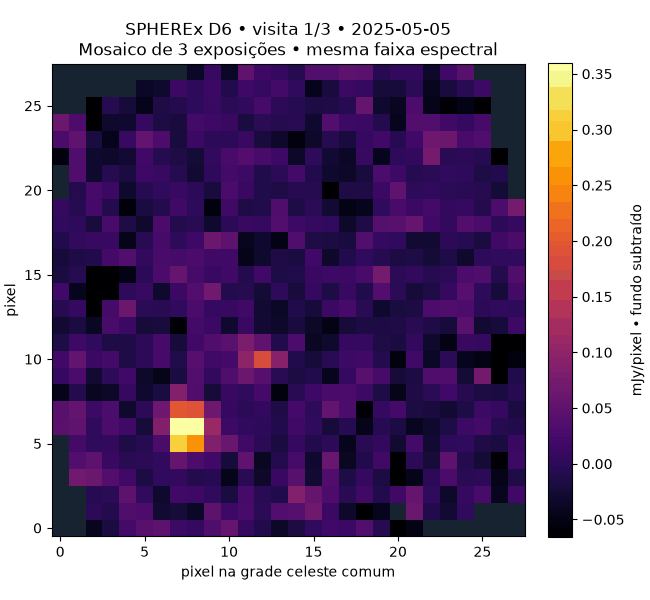

In [1]:
from pathlib import Path
from IPython.display import Image, display
from astropy.table import Table

ROOT = Path.cwd()
if not (ROOT / "outputs").exists():
    ROOT = ROOT.parent
OUT = ROOT / "outputs/three_visits"
display(Image(filename=str(OUT / "spherex_three_visits.gif")))

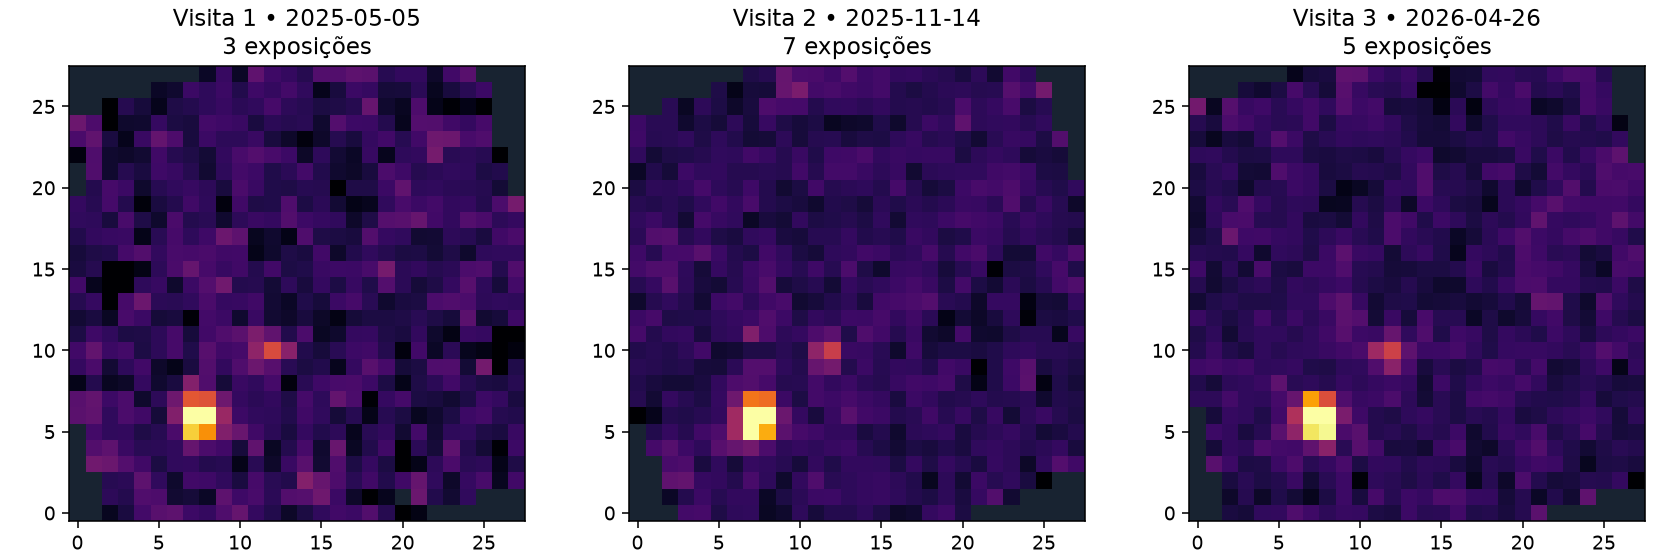

visit,date,aperture_sum_mjy,background_mjy_per_pixel,aperture_flux_background_subtracted_mjy
int64,str23,float64,float64,float64
1,2025-05-05T16:49:00.018,1.0493976809979706,0.03649139791237263,-0.24485456737125055
2,2025-11-14T12:12:36.814,0.94295786835068,0.021233453012548087,0.18986410175603763
3,2026-04-26T02:04:05.705,0.8334313839856469,0.031219744920226306,-0.2738494374710858


In [2]:
display(Image(filename=str(OUT / "three_visits.png")))
Table.read(OUT / "photometry.csv", format="ascii.csv")

## As mesmas três imagens no Aladin

In [3]:
from spherex_tracking.three_visits import three_visit_viewer

viewer = three_visit_viewer(OUT / "report.json")
viewer